# 04 — Detector noise, cube reconstruction, SNR

**Portfolio / learning project — not a calibrated instrument simulator.** All quantities below are synthetic proxies, literature-derived presets, or engineering estimates (see the [provenance table](../docs/model_details.md#data-provenance)).

This notebook is narrative and self-contained; run the cells top to bottom.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent / 'src'))
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
FIG = pathlib.Path.cwd().parent / 'figures' / 'notebooks'
FIG.mkdir(parents=True, exist_ok=True)


## Add noise, then invert — two estimators
We expose the detector frame (Poisson + read + dark + flat + bad pixels), remove the known bias/dark/response as the pipeline does, and rebuild the cube two ways:

* **nearest** reads each voxel's own detector pixel. This is the pipeline default: noise stays independent and the cross-talk is left as a small extra spatial blur.
* **deblend** jointly inverts the cross-talk with inverse-variance least squares.

Each estimator returns its *own* matching variance cube; never pair one estimator's flux with the other's variance.

In [2]:
from ao_fed_ifu.source_cube import SourceCubeConfig, create_emission_line_cube, scale_cube_to_total_electrons
from ao_fed_ifu.spectrograph_model import SpectrographConfig
from ao_fed_ifu.ifu_mapping import IFUConfig, build_slicer_mapping, forward_project_cube
from ao_fed_ifu.detector_model import DetectorConfig, calibrate_readout, expose
from ao_fed_ifu import cube_reconstruction as recon
from ao_fed_ifu import diagnostics as diag

spectro = SpectrographConfig(lambda_min_um=2.0, lambda_max_um=2.3, resolving_power_R=2500.0)
cfg = SourceCubeConfig(nx=12, ny=12, nlambda=spectro.n_detector_pixels, lambda_min_um=2.0, lambda_max_um=2.3)
wl = cfg.wavelength_grid_um; centre = spectro.lambda_mid_um
cube = create_emission_line_cube(cfg, line_center_um=centre, line_flux_rel=12.0,
        line_sigma_um=0.0003, velocity_gradient_kms_per_spaxel=15.0)
cube = scale_cube_to_total_electrons(cube, 3e6)
ifu = IFUConfig(nx_spaxel=cfg.nx, ny_spaxel=cfg.ny, cross_talk_sigma_pix=0.6)
mapping = build_slicer_mapping(ifu, spectro, wl)
frame = forward_project_cube(cube, mapping)
det = DetectorConfig(read_noise_e=10.0)
readout = expose(frame, det, exposure_s=600.0, rng=0)
# Remove the known bias/dark expectation and pixel response (as the pipeline
# does) before extraction; bad and saturated pixels stay masked.
calibrated = calibrate_readout(readout, det, exposure_s=600.0)
products = {}
for method in ('nearest', 'deblend'):
    rebuilt, var_cube = recon.reconstruct_cube_with_variance(
        calibrated.image_e, calibrated.variance_e2, mapping, method=method)
    products[method] = (rebuilt, var_cube)
print('reconstructed cube shape:', rebuilt.shape)

reconstructed cube shape: (12, 12, 873)


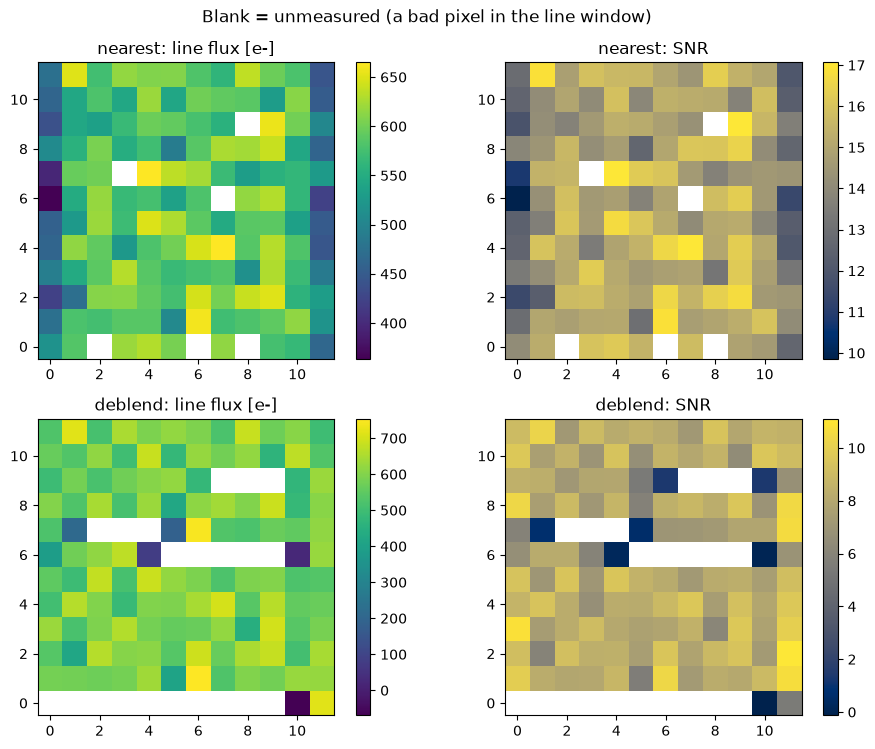

,method,measured_spaxel_fraction,median_snr
0,nearest,0.958333,14.941628
1,deblend,0.854167,8.217564


In [3]:
window = 0.0012
fig, ax = plt.subplots(2, 2, figsize=(9.5, 7.6))
rows = []
for i, (method, (rebuilt, var_cube)) in enumerate(products.items()):
    lf = diag.line_flux_map(rebuilt, wl, centre, window, variance_cube=var_cube)  # same mask as SNR
    snr = diag.snr_map(rebuilt, var_cube, wl, centre, window)
    im0 = ax[i, 0].imshow(lf, origin='lower', cmap='viridis'); plt.colorbar(im0, ax=ax[i, 0])
    im1 = ax[i, 1].imshow(snr, origin='lower', cmap='cividis'); plt.colorbar(im1, ax=ax[i, 1])
    ax[i, 0].set_title(f'{method}: line flux [e-]'); ax[i, 1].set_title(f'{method}: SNR')
    rows.append({'method': method, 'measured_spaxel_fraction': float(np.isfinite(snr).mean()),
                 'median_snr': float(np.nanmedian(snr))})
fig.suptitle('Blank = unmeasured (a bad pixel in the line window)')
fig.tight_layout(); fig.savefig(FIG / 'nb04_snr_map.png', dpi=110); plt.show()
pd.DataFrame(rows)

In this model each spaxel owns exactly one detector row, so the deblend has almost no spare data. It removes the cross-talk blur, but it roughly halves the per-spaxel SNR, and a single bad pixel can leave a run of neighbouring spaxels unmeasured. The pipeline defaults to `science_extraction="nearest"` for this one-pixel geometry; this direct read-out does not reproduce a real pipeline's resampling. The deblend stays available for trade studies.

## SNR scales as sqrt(exposure) in the photon limit

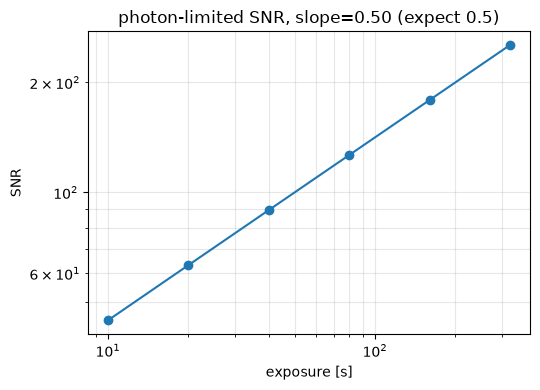

In [4]:
rn = DetectorConfig(read_noise_e=3.0, dark_current_e_s_pix=0.0)
rate = 200.0
ts = np.array([10, 20, 40, 80, 160, 320.0])
snr_t = []
for t in ts:
    var = rate*t + rn.read_noise_e**2
    snr_t.append(rate*t / np.sqrt(var))
slope = np.polyfit(np.log(ts), np.log(snr_t), 1)[0]
fig, ax = plt.subplots(figsize=(5.5, 4))
ax.loglog(ts, snr_t, 'o-'); ax.set_xlabel('exposure [s]'); ax.set_ylabel('SNR')
ax.set_title(f'photon-limited SNR, slope={slope:.2f} (expect 0.5)'); ax.grid(alpha=0.3, which='both')
fig.tight_layout(); fig.savefig(FIG / 'nb04_snr_sqrt_t.png', dpi=110); plt.show()
pd.DataFrame({'exposure_s': ts, 'snr': snr_t}).to_csv(FIG / 'nb04_summary.csv', index=False)